**FastAPI – Project 2: Introduction and Book Class**

Project 2 builds on the HTTP methods we learned in Project 1. 
This time, we'll make our API more structured by working with Python objects instead of dictionaries.

We'll also introduce data validation, exception handling, HTTP status codes, Swagger configuration, and Python request objects.

**Q1) how FastAPI automatically converts these Python objects into JSON responses.**

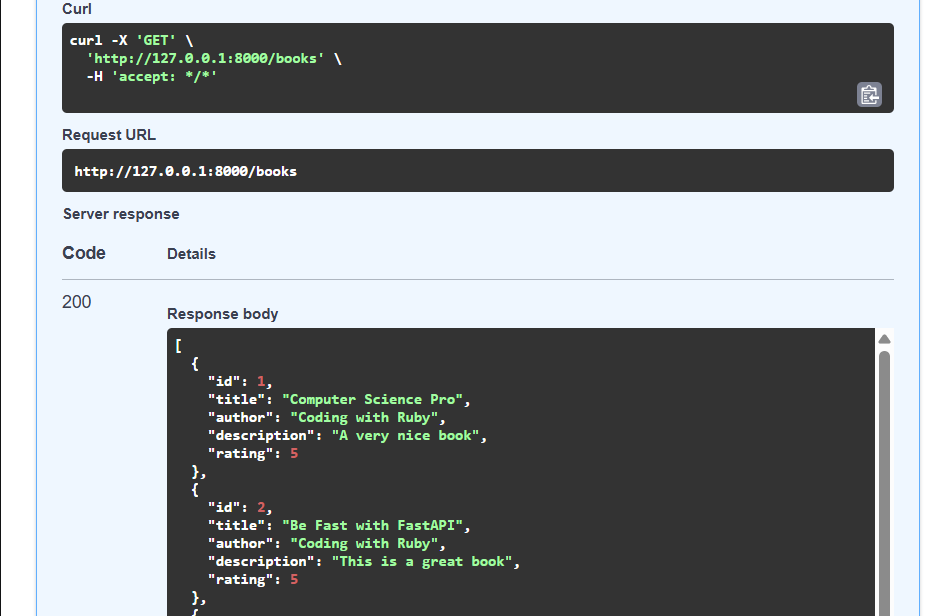
Here I was sending a list of python object i.e. books 
then why I am seeing Json in response 

In [1]:
class Book:
    id: int
    title: str
    author: str
    description: str
    rating: int

    def __init__(self, id, title, author, description, rating):
        self.id = id
        self.title = title
        self.author = author
        self.description = description
        self.rating = rating

In [4]:
print(Book(1, "Computer Science Pro", "Coding with Ruby", "A very nice book", 5   ))

In [6]:
print(Book(1, "Computer Science Pro", "Coding with Ruby", "A very nice book", 5   ).__dict__)

{'id': 1, 'title': 'Computer Science Pro', 'author': 'Coding with Ruby', 'description': 'A very nice book', 'rating': 5}


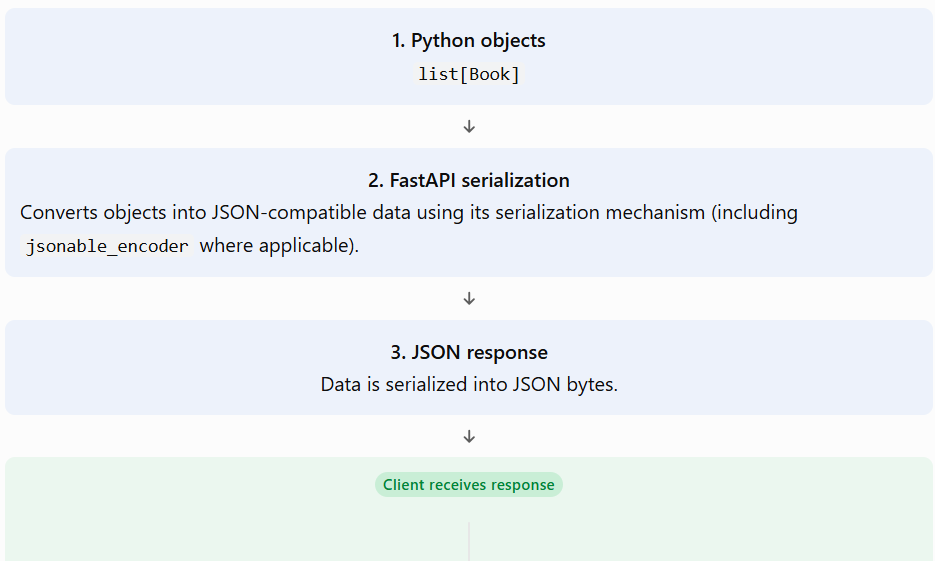

The diagram illustrates how FastAPI processes a returned list of custom objects—specifically list[Book]—and turns it into an HTTP response.
Here is what happens at each stage of the flowchart using a concrete code example:

Step 1: Python Objects (list[Book])

Your endpoint function finishes executing and returns a native Python list containing Book instances (whether they are Pydantic models, dataclasses, or ORM objects like SQLAlchemy models).

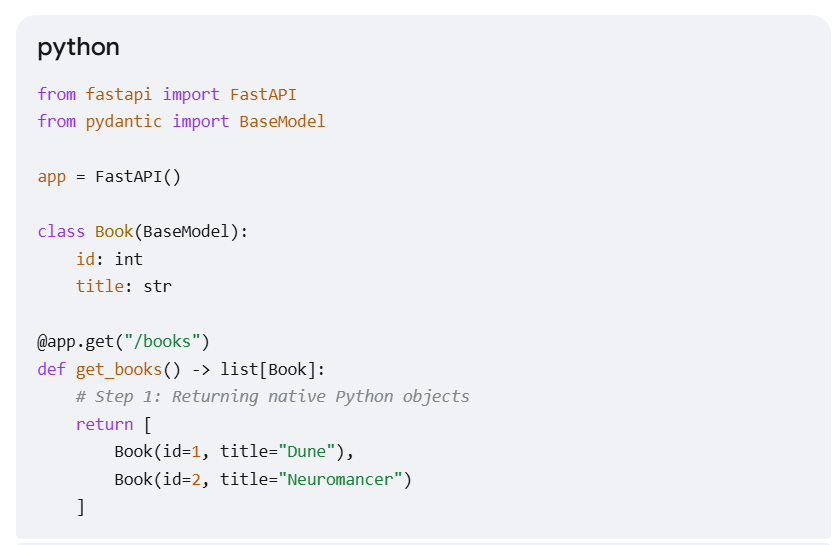

Step 2: FastAPI Serialization

FastAPI intercepts the returned list[Book] before sending it over the network:

• If Book is a Pydantic model (or a **response_model** is set): FastAPI uses Pydantic's internal serializer to validate the fields and map the objects directly into a JSON-compatible structure.

• If Book is a standard class, dataclass, or ORM model without a response_model: FastAPI passes the list through **jsonable_encoder**, which recursively unpacks each Book instance into a standard Python dict containing only JSON-safe primitives (int, str, float, bool, None).
At the end of this step, your data is represented internally as JSON-compatible structures:

[{"id": 1, "title": "Dune"}, {"id": 2, "title": "Neuromancer"}]



Step 3: JSON Response

FastAPI wraps the serialized data inside a JSONResponse object:

• The Python structure is encoded into a raw UTF-8 JSON byte string: b'[{"id":1,"title":"Dune"},{"id":2,"title":"Neuromancer"}]'.

• FastAPI automatically attaches the HTTP header Content-Type: application/json so the client knows how to parse the incoming bytes.
